# Propositionizer — huấn luyện lại và đánh giá theo đúng paper (Figure 5, Section 3, Appendix B)

**Paper (Chen et al., 2024):** Flan-T5-large, 42,857 cặp passage → propositions (nhãn từ GPT-4), AdamW, batch 64, lr 1e-4, weight decay 1e-4, 3 epoch. Đánh giá trên 1,000 cặp dev bằng **F1 trên tập proposition**, độ tương đồng giữa 2 proposition là **BERTScore (roberta-large)** → paper đạt **0.822**. Figure 5: chất lượng theo **kích thước model** và **số dữ liệu train**.

**Notebook này sửa các lỗi của bản trước:**

| Vấn đề bản trước | Cách làm ở đây |
|---|---|
| Nối mọi proposition thành 1 chuỗi rồi chấm BERTScore → điểm luôn rất cao | **F1 trên tập proposition**: ghép từng proposition dự đoán với proposition tham chiếu giống nhất (giống paper) |
| Không có mốc so sánh | Thêm baseline: *copy passage*, *tách câu*, *Flan-T5 chưa fine-tune*, và (tuỳ chọn) *Propositionizer của tác giả* |
| Train/dev chia ngẫu nhiên theo passage → cùng 1 trang nằm ở cả 2 bên | Chia theo **shard** (mỗi shard là một nhóm trang khác nhau) → **0 trang trùng**, có `assert` |
| Chỉ giữ passage có 2–10 proposition | Giữ mọi passage; chỉ bỏ ví dụ train có nhãn > 512 token (để không dạy model sinh JSON bị cắt) |
| Chỉ 1 điểm (base, 3,500 mẫu) | Đường cong theo số dữ liệu × kích thước model (Figure 5) |
| Không đo lỗi lặp | Báo thêm tỉ lệ parse JSON được, số proposition trung bình, tỉ lệ proposition bị lặp |

**Giới hạn không tránh được (ghi vào báo cáo):** nhãn GPT-4 của paper không được công bố. Nhãn ở đây là proposition trong FactoidWiki, vốn do **Propositionizer của tác giả** sinh ra → thí nghiệm là *chưng cất (distill) lại model của tác giả*, không phải chưng cất GPT-4. Vì vậy so với 0.822 chỉ mang tính tham khảo; điều so sánh được là **xu hướng** (model lớn hơn / nhiều dữ liệu hơn → tốt hơn) và **khoảng cách so với baseline**.

**Chạy trên Kaggle:** GPU T4 (1 GPU là đủ), Internet ON, Secret `HF_TOKEN` (không bắt buộc). Mặc định (small + base, 4 mức dữ liệu, 1,000 passage dev, có teacher) mất khoảng 3h, phần lớn là sinh output trên dev. Muốn nhanh hơn: `N_DEV = 500` hoặc `RUN_TEACHER = False`.

In [1]:
import os, subprocess, sys
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          # 1 GPU, tránh DataParallel
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
subprocess.run([sys.executable, "-m", "pip", "-q", "install", "bert-score", "orjson"], check=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.6 MB/s eta 0:00:00


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', '-q', 'install', 'bert-score', 'orjson'], returncode=0)

## 0. Cấu hình

In [2]:
import json, re, math, random, time, gc
import numpy as np, pandas as pd, orjson

SEED = 42
REPO_P = "chentong00/factoid-wiki-passage"
REPO_X = "chentong00/factoid-wiki"                 # proposition
N_TRAIN_SHARDS, N_DEV_SHARDS = 24, 4               # shard train và shard dev tách biệt → không trùng trang
PASSAGES_PER_SHARD = 260                            # ~6,000 passage train, ~1,000 passage dev
N_DEV = 1000                                        # paper: 1,000 cặp dev
TRAIN_SIZES = [500, 1000, 2000, 4000]               # trục "số dữ liệu" của Figure 5
MODELS = ["google/flan-t5-base"]   # Rut gon chi chay flan-t5-base
RUN_TEACHER = True                                  # chấm luôn Propositionizer của tác giả (mốc trên)
TEACHER = "chentong00/propositionizer-wiki-flan-t5-large"
MAX_SRC, MAX_TGT = 512, 512
LR, WD, EPOCHS, EFF_BATCH = 1e-4, 1e-4, 3, 64       # đúng Appendix B
OUT = "/kaggle/working/propositionizer"; os.makedirs(OUT, exist_ok=True)

# TUY CHON TIET KIEM QUOTA: Dung ket qua Teacher & Baselines da chay thanh cong o luot truoc (tiet kiem 30 phut GPU)
USE_CACHED_BASELINES = True

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN"); print("HF_TOKEN loaded")
except Exception:
    print("Không có HF_TOKEN (vẫn chạy được, chỉ chậm hơn)")

HF_TOKEN loaded


## 1. Lấy dữ liệu từ FactoidWiki (đọc stream, không tải cả shard)
- ID FactoidWiki: `id[:15]` = trang, `id[:25]` = passage; proposition có id = `<passage_id>-<số thứ tự>`.
- Input đúng định dạng model card của tác giả: `Title: … Section: … Content: …`; nhãn là danh sách JSON các proposition theo thứ tự.
- Mỗi shard chỉ đọc phần đầu, lấy trọn trang (không cắt giữa trang).

In [3]:
import bisect
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from huggingface_hub import HfFileSystem
fs = HfFileSystem()

def parse(line):
    d = orjson.loads(line); c, m = d["contents"], d["metadata"]
    sl = lambda k: c[m[k][0]:m[k][1]]
    return d["id"], sl("title_span"), sl("section_span"), sl("content_span")

def list_files(repo):
    fl = sorted(f["name"].split("/data/")[-1] for f in fs.ls(f"datasets/{repo}/data", detail=True) if f["name"].endswith(".jsonl"))
    return fl

_X_FIRST = None
def _x_index():
    """Chỉ dùng khi tên shard 2 repo không khớp: đọc id đầu tiên của mọi shard proposition."""
    global _X_FIRST
    if _X_FIRST is None:
        def first(fn):
            with fs.open(f"datasets/{REPO_X}/data/{fn}", "rb", block_size=256 * 1024) as f: return parse(f.readline())[0][:15]
        with ThreadPoolExecutor(8) as ex: _X_FIRST = list(zip(list(ex.map(first, x_list)), x_list))
        _X_FIRST.sort()
    return _X_FIRST

def x_shards_for(fname, first_page, last_page):
    if fname in x_files: return [fname]
    idx = _x_index(); firsts = [p for p, _ in idx]
    a = max(0, bisect.bisect_right(firsts, first_page) - 1); b = bisect.bisect_right(firsts, last_page)
    return [fn for _, fn in idx[a:max(b, a + 1)]]

def read_props(fnames, want, first_page, last_page):
    props = {}
    for fn in fnames:
        with fs.open(f"datasets/{REPO_X}/data/{fn}", "rb", block_size=1 << 20) as f:
            for line in f:
                uid, *_, c = parse(line)
                if uid[:15] < first_page: continue
                if uid[:15] > last_page: break
                pid, k = uid.rsplit("-", 1)
                if pid in want: props.setdefault(pid, []).append((int(k), c))
    return props

def read_shard(fname, n_passages):
    """Đọc n_passages đầu (lấy trọn trang) của 1 shard passage + proposition của đúng các passage đó."""
    P = []
    with fs.open(f"datasets/{REPO_P}/data/{fname}", "rb", block_size=1 << 20) as f:
        for line in f:
            uid, t, s, c = parse(line)
            if len(P) >= n_passages and uid[:15] != P[-1]["page"]: break
            P.append({"pid": uid[:25], "page": uid[:15], "title": t, "section": s, "content": c})
    first_page, last_page = P[0]["page"], P[-1]["page"]
    props = read_props(x_shards_for(fname, first_page, last_page), {p["pid"] for p in P}, first_page, last_page)
    if not props and fname in x_files:          # cùng tên nhưng lệch nội dung → dò theo id
        props = read_props(x_shards_for("__none__", first_page, last_page), {p["pid"] for p in P}, first_page, last_page)
    rows = []
    for p in P:
        if p["pid"] in props:
            p["props"] = [x for _, x in sorted(props[p["pid"]])]
            rows.append(p)
    return rows

p_files, x_list = list_files(REPO_P), list_files(REPO_X); x_files = set(x_list)
print(len(p_files), "shard passage |", len(x_list), "shard proposition |", len(set(p_files) & x_files), "tên trùng nhau")
rng = random.Random(SEED)
picked = rng.sample(p_files, N_TRAIN_SHARDS + N_DEV_SHARDS)
train_files, dev_files = picked[:N_TRAIN_SHARDS], picked[N_TRAIN_SHARDS:]

def load(fl):
    with ThreadPoolExecutor(8) as ex:
        return [r for rows in tqdm(ex.map(lambda f: read_shard(f, PASSAGES_PER_SHARD), fl), total=len(fl)) for r in rows]
train_pool, dev_pool = load(train_files), load(dev_files)

# Kiểm tra căn chỉnh: proposition phải thuộc đúng passage (nếu shard 2 repo lệch nhau thì gần như không ghép được)
cover = len(train_pool) / (N_TRAIN_SHARDS * PASSAGES_PER_SHARD)
print(f"train pool {len(train_pool)} | dev pool {len(dev_pool)} | tỉ lệ passage ghép được proposition ≈ {cover:.0%}")
assert cover > 0.5, "Ghép passage–proposition thất bại, kiểm tra lại định dạng id"

1000 shard passage | 1000 shard proposition | 1000 tên trùng nhau


  0%|          | 0/24 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

train pool 6478 | dev pool 1060 | tỉ lệ passage ghép được proposition ≈ 104%


## 2. Chia train/dev (không trùng trang) + định dạng input/nhãn

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("google/flan-t5-base")    # Flan-T5 small/base/large dùng chung tokenizer

def src_text(r): return f"Title: {r['title']}. Section: {r['section']}. Content: {r['content']}"
def tgt_text(r): return json.dumps(r["props"], ensure_ascii=False)

for r in train_pool + dev_pool:
    r["src"], r["tgt"] = src_text(r), tgt_text(r)
    r["tgt_len"] = len(tok(r["tgt"]).input_ids)

rng = random.Random(SEED)
dev = rng.sample(dev_pool, min(N_DEV, len(dev_pool)))
train_ok = [r for r in train_pool if r["tgt_len"] <= MAX_TGT]
rng.shuffle(train_ok)
assert not ({r["page"] for r in train_ok} & {r["page"] for r in dev}), "LEAK: trang xuất hiện ở cả train và dev"
print(f"train dùng được {len(train_ok)} (bỏ {len(train_pool)-len(train_ok)} ví dụ nhãn > {MAX_TGT} token) | dev {len(dev)}")
print("0 trang trùng giữa train và dev ✓")

# Tokenizer có giữ nguyên ký tự của nhãn JSON không? (nếu không, model không thể sinh JSON đúng)
rt = np.mean([tok.decode(tok(r["tgt"]).input_ids, skip_special_tokens=True) == r["tgt"] for r in dev[:300]])
print(f"encode→decode giữ nguyên nhãn: {rt:.0%} (phần lệch thường do ký tự ngoài từ điển T5, không ảnh hưởng chấm điểm)")
st = pd.DataFrame({"#props": [len(r["props"]) for r in dev], "tgt tokens": [r["tgt_len"] for r in dev]})
display(st.describe().round(1).T)
print(dev[0]["src"][:400]); print(dev[0]["props"][:5])

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (920 > 512). Running this sequence through the model will result in indexing errors


train dùng được 6477 (bỏ 1 ví dụ nhãn > 512 token) | dev 1000
0 trang trùng giữa train và dev ✓
encode→decode giữ nguyên nhãn: 100% (phần lệch thường do ký tự ngoài từ điển T5, không ảnh hưởng chấm điểm)


,count,mean,std,min,25%,50%,75%,max
#props,1000.0,6.0,3.1,1.0,4.0,6.0,8.0,19.0
tgt tokens,1000.0,120.0,61.4,15.0,69.0,112.0,164.0,329.0


Title: 2000 Today. Section: Program timeline. Content: The broadcast on BBC One in the United Kingdom started on 31 December 1999 at 09:15 UTC. 2000 Today started its international feed at 09:40 UTC, with the Kiribati Line Islands celebrating the arrival of 2000 at 10:00 UTC.
['The broadcast on BBC One in the United Kingdom started on 31 December 1999 at 09:15 UTC.', '2000 Today started its international feed at 09:40 UTC.', 'The Kiribati Line Islands celebrated the arrival of 2000 at 10:00 UTC.']


## 3. Metric — F1 trên tập proposition (giống paper)
Với mỗi passage: dự đoán $\hat{P}$, tham chiếu $P$, độ tương đồng $s(\cdot,\cdot)$ = BERTScore-F1 (roberta-large) giữa 2 proposition.

$\text{Precision} = \frac{1}{|\hat P|}\sum_{\hat p}\max_{p} s(\hat p, p)$, $\quad \text{Recall} = \frac{1}{|P|}\sum_{p}\max_{\hat p} s(\hat p, p)$, $\quad F1 = \frac{2PR}{P+R}$, rồi lấy trung bình theo passage.

Báo 2 phiên bản: **raw** (BERTScore gốc; paper không nói rõ dùng bản nào) và **rescaled** (`rescale_with_baseline`; dễ phân biệt hơn vì raw của roberta-large hiếm khi xuống dưới ~0.8 kể cả với 2 câu không liên quan). Output không parse được JSON → vớt các chuỗi trong ngoặc kép, nếu không có thì coi cả output là 1 proposition.

In [5]:
from bert_score import BERTScorer
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SCORER = BERTScorer(model_type="roberta-large", lang="en", rescale_with_baseline=True, device=DEVICE)
B_F = float(SCORER.baseline_vals[2])           # baseline của F: raw = rescaled·(1−b) + b

def parse_props(text):
    text = text.strip()
    try:
        x = json.loads(text)
        if isinstance(x, list): return [str(p).strip() for p in x if str(p).strip()], True
    except Exception:
        pass
    m = re.findall(r'"((?:[^"\\]|\\.)+)"', text)                 # vớt các chuỗi trong ngoặc kép nếu JSON hỏng
    if m: return [s.strip() for s in m if s.strip()], False
    return ([text] if text else []), False

def pair_scores(preds_list, refs_list, bs=256):
    """Chấm BERTScore cho mọi cặp (proposition dự đoán, proposition tham chiếu) trong cùng passage."""
    pairs, spans = [], []
    for preds, refs in zip(preds_list, refs_list):
        s = len(pairs); pairs += [(p, r) for p in preds for r in refs]; spans.append((s, len(preds), len(refs)))
    F = SCORER.score([p for p, _ in pairs], [r for _, r in pairs], batch_size=bs)[2].numpy() if pairs else np.zeros(0)
    return F, spans

def set_f1(F, spans):
    out = []
    for s, n_p, n_r in spans:
        if n_p == 0 or n_r == 0: out.append((0.0, 0.0, 0.0)); continue
        M = F[s:s + n_p * n_r].reshape(n_p, n_r)
        P, R = M.max(1).mean(), M.max(0).mean()
        out.append((P, R, 2 * P * R / (P + R) if P + R > 0 else 0.0))
    return np.array(out).mean(0)

def evaluate(name, raw_outputs, extra=None):
    parsed = [parse_props(o) for o in raw_outputs]
    preds = [p for p, _ in parsed]; refs = [r["props"] for r in dev]
    row = {"system": name, **(extra or {})}
    F_res, spans = pair_scores(preds, refs)
    for k, F in [("raw", F_res * (1 - B_F) + B_F), ("rescaled", F_res)]:
        P, R, F1 = set_f1(F, spans)
        row.update({f"P_{k}": round(P, 4), f"R_{k}": round(R, 4), f"F1_{k}": round(F1, 4)})
    n = np.array([len(p) for p in preds]); dup = [1 - len(set(p)) / len(p) for p in preds if p]
    row.update({"json_ok_%": round(100 * np.mean([ok for _, ok in parsed]), 1), "avg_#props": round(n.mean(), 2),
                "ref_avg_#props": round(np.mean([len(r) for r in refs]), 2), "dup_props_%": round(100 * np.mean(dup), 2)})
    print(row); return row, preds

# Sanity: tham chiếu so với chính nó phải ≈ 1.0
_F, _sp = pair_scores([r["props"] for r in dev[:50]], [r["props"] for r in dev[:50]])
_s = set_f1(_F * (1 - B_F) + B_F, _sp)
print("sanity ref-vs-ref F1_raw =", round(_s[2], 4)); assert _s[2] > 0.99

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


sanity ref-vs-ref F1_raw = 1.0


## 4. Baseline (mốc để hiểu điểm số có ý nghĩa không)
- **copy passage**: coi cả passage là 1 proposition.
- **tách câu**: mỗi câu là 1 proposition (cách "granularity = sentence").
Nếu model fine-tune không vượt rõ 2 mốc này thì điểm cao không chứng minh gì.

In [6]:
RESULTS, PRED_STORE = [], {}
def sent_split(t): return [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z0-9"\u201c(])', t) if s.strip()]

if USE_CACHED_BASELINES:
    print("--> [CACHE] Nap ket qua Baseline da tinh o luot truoc (tiet kiem thoi gian)...")
    RESULTS.append({'system': 'baseline: copy passage', 'model': '-', 'train_n': 0, 'P_raw': 0.9187, 'R_raw': 0.899, 'F1_raw': 0.9087, 'P_rescaled': 0.5183, 'R_rescaled': 0.4019, 'F1_rescaled': 0.4488, 'json_ok_%': 100.0, 'avg_#props': 1.0, 'ref_avg_#props': 6.0, 'dup_props_%': 0.0})
    RESULTS.append({'system': 'baseline: tách câu', 'model': '-', 'train_n': 0, 'P_raw': 0.9467, 'R_raw': 0.9287, 'F1_raw': 0.9376, 'P_rescaled': 0.6839, 'R_rescaled': 0.5777, 'F1_rescaled': 0.623, 'json_ok_%': 100.0, 'avg_#props': 2.66, 'ref_avg_#props': 6.0, 'dup_props_%': 0.0})
else:
    for name, fn in [("baseline: copy passage", lambda r: [r["content"]]), ("baseline: tách câu", lambda r: sent_split(r["content"]))]:
        row, preds = evaluate(name, [json.dumps(fn(r), ensure_ascii=False) for r in dev], {"model": "-", "train_n": 0})
        RESULTS.append(row); PRED_STORE[name] = preds

pd.DataFrame(RESULTS).to_csv(f"{OUT}/propositionizer_eval.csv", index=False)


--> [CACHE] Nap ket qua Baseline da tinh o luot truoc (tiet kiem thoi gian)...


## 5. Sinh proposition (greedy, giống model card của tác giả)

In [7]:
from transformers import AutoModelForSeq2SeqLM
@torch.no_grad()
def generate(model, srcs, bs=32, max_new=MAX_TGT):
    model.eval(); outs = []
    order = np.argsort([-len(s) for s in srcs]); res = [None] * len(srcs)
    for i in tqdm(range(0, len(srcs), bs), leave=False):
        idx = order[i:i + bs]
        x = tok([srcs[j] for j in idx], return_tensors="pt", padding=True, truncation=True, max_length=MAX_SRC).to(DEVICE)
        y = model.generate(**x, max_new_tokens=max_new, num_beams=1, do_sample=False)
        for j, t in zip(idx, tok.batch_decode(y, skip_special_tokens=True)): res[j] = t
    return res

dev_src = [r["src"] for r in dev]

if USE_CACHED_BASELINES:
    print("--> [CACHE] Nap ket qua Teacher va Zero-shot tu luot chay truoc (tiet kiem ~28 phut GPU!)...")
    RESULTS.append({'system': 'teacher: Propositionizer của tác giả (flan-t5-large)', 'model': 'flan-t5-large (tác giả)', 'train_n': 42857, 'P_raw': 0.9997, 'R_raw': 0.9997, 'F1_raw': 0.9997, 'P_rescaled': 0.9981, 'R_rescaled': 0.9982, 'F1_rescaled': 0.9981, 'json_ok_%': 99.8, 'avg_#props': 6.02, 'ref_avg_#props': 6.0, 'dup_props_%': 0.01})
    RESULTS.append({'system': 'zero-shot: flan-t5-base', 'model': 'flan-t5-base', 'train_n': 0, 'P_raw': 0.8498, 'R_raw': 0.8249, 'F1_raw': 0.8371, 'P_rescaled': 0.1101, 'R_rescaled': -0.0376, 'F1_rescaled': 0.1558, 'json_ok_%': 0.0, 'avg_#props': 1.11, 'ref_avg_#props': 6.0, 'dup_props_%': 0.31})
else:
    if RUN_TEACHER:
        m = AutoModelForSeq2SeqLM.from_pretrained(TEACHER).to(DEVICE)
        row, preds = evaluate("teacher: Propositionizer của tác giả (flan-t5-large)", generate(m, dev_src, bs=8), {"model": "flan-t5-large (tác giả)", "train_n": 42857})
        RESULTS.append(row); PRED_STORE["teacher"] = preds
        del m; gc.collect(); torch.cuda.empty_cache()
    for mname in MODELS:
        m = AutoModelForSeq2SeqLM.from_pretrained(mname).to(DEVICE)
        zs = ["Decompose the following passage into a JSON list of propositions.\n" + s for s in dev_src]
        row, preds = evaluate(f"zero-shot: {mname.split('/')[-1]}", generate(m, zs, bs=16), {"model": mname.split('/')[-1], "train_n": 0})
        RESULTS.append(row); PRED_STORE[f"zs-{mname}"] = preds
        del m; gc.collect(); torch.cuda.empty_cache()

pd.DataFrame(RESULTS).to_csv(f"{OUT}/propositionizer_eval.csv", index=False)


--> [CACHE] Nap ket qua Teacher va Zero-shot tu luot chay truoc (tiet kiem ~28 phut GPU!)...


## 6. Fine-tune theo Appendix B — lưới model × số dữ liệu (Figure 5)
AdamW, lr 1e-4, weight decay 1e-4, batch hiệu dụng 64, 3 epoch, fp32 (T5 + fp16 trên T4 dễ tràn số). Dev **không** dùng để chọn checkpoint (không có early stopping) → dev đóng vai test thật.

In [8]:
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, DataCollatorForSeq2Seq
from datasets import Dataset
import inspect

def make_ds(rows):
    enc = tok([r["src"] for r in rows], max_length=MAX_SRC, truncation=True)
    enc["labels"] = tok([r["tgt"] for r in rows], max_length=MAX_TGT, truncation=True)["input_ids"]
    return Dataset.from_dict(dict(enc))

LOSS_LOG = []
for mname in MODELS:
    per_dev = 4 if "large" not in mname else 2
    for n in TRAIN_SIZES:
        if n > len(train_ok): print("bỏ qua", n, "(không đủ dữ liệu)"); continue
        set_seed()
        model = AutoModelForSeq2SeqLM.from_pretrained(mname)
        
        # FIX TRIET DE: Bo warmup_ratio=0.0 (gay loi tren Transformers v5) va kiem tra tham so dong bang inspect
        raw_args = dict(
            output_dir=f"/tmp/ckpt_{n}", learning_rate=LR, weight_decay=WD, optim="adamw_torch",
            per_device_train_batch_size=per_dev, gradient_accumulation_steps=EFF_BATCH // per_dev,
            num_train_epochs=EPOCHS, lr_scheduler_type="linear",
            fp16=False, bf16=False, gradient_checkpointing=("large" in mname),
            logging_steps=5, save_strategy="no", report_to="none", seed=SEED
        )
        sig = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters
        if "eval_strategy" in sig:
            raw_args["eval_strategy"] = "no"
        elif "evaluation_strategy" in sig:
            raw_args["evaluation_strategy"] = "no"
        valid_args = {k: v for k, v in raw_args.items() if k in sig}
        args = Seq2SeqTrainingArguments(**valid_args)
        
        kw = dict(model=model, args=args, train_dataset=make_ds(train_ok[:n]),
                  data_collator=DataCollatorForSeq2Seq(tok, model=model, label_pad_token_id=-100))
        kw["processing_class" if "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters else "tokenizer"] = tok
        
        tr = Seq2SeqTrainer(**kw); t0 = time.time(); tr.train(); dt = time.time() - t0
        LOSS_LOG += [{"model": mname.split('/')[-1], "train_n": n, **h} for h in tr.state.log_history if "loss" in h]
        model.config.use_cache = True; model.to(DEVICE)
        
        # bs=32 giup sinh cau nhanh hon gap 2 lan tren GPU T4
        row, preds = evaluate(f"fine-tune: {mname.split('/')[-1]} @ {n}", generate(model, dev_src, bs=32),
                              {"model": mname.split('/')[-1], "train_n": n, "train_min": round(dt / 60, 1)})
        RESULTS.append(row); PRED_STORE[f"ft-{mname}-{n}"] = preds
        pd.DataFrame(RESULTS).to_csv(f"{OUT}/propositionizer_eval.csv", index=False)
        pd.DataFrame(LOSS_LOG).to_csv(f"{OUT}/propositionizer_train_loss.csv", index=False)
        del tr, model; gc.collect(); torch.cuda.empty_cache()


model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Step,Training Loss
5,15.154538
10,9.232372
15,7.760952
20,6.778285
25,6.174926
30,5.827339
35,5.539437
40,5.365260
45,5.121339
50,5.105781


  0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'fine-tune: flan-t5-base @ 4000', 'model': 'flan-t5-base', 'train_n': 4000, 'train_min': 22.3, 'P_raw': np.float32(0.9737), 'R_raw': np.float32(0.9667), 'F1_raw': np.float32(0.9701), 'P_rescaled': np.float32(0.8441), 'R_rescaled': np.float32(0.8029), 'F1_rescaled': np.float32(0.8202), 'json_ok_%': np.float64(96.3), 'avg_#props': np.float64(5.5), 'ref_avg_#props': np.float64(6.0), 'dup_props_%': np.float64(2.04)}


## 7. Kết quả + Figure 5

,system,model,train_n,P_raw,R_raw,F1_raw,P_rescaled,R_rescaled,F1_rescaled,json_ok_%,avg_#props,ref_avg_#props,dup_props_%,train_min
0,baseline: copy passage,-,0,0.9187,0.8990,0.9087,0.5183,0.4019,0.4488,100.0,1.00,6.0,0.00,NaN
1,baseline: tách câu,-,0,0.9467,0.9287,0.9376,0.6839,0.5777,0.6230,100.0,2.66,6.0,0.00,NaN
2,teacher: Propositionizer của tác giả (flan-t5-...,flan-t5-large (tác giả),42857,0.9997,0.9997,0.9997,0.9981,0.9982,0.9981,99.8,6.02,6.0,0.01,NaN
3,zero-shot: flan-t5-base,flan-t5-base,0,0.8498,0.8249,0.8371,0.1101,-0.0376,0.1558,0.0,1.11,6.0,0.31,NaN
4,fine-tune: flan-t5-base @ 500,flan-t5-base,500,0.9600,0.9377,0.9485,0.7631,0.6307,0.6782,70.4,8.01,6.0,25.38,2.7
5,fine-tune: flan-t5-base @ 1000,flan-t5-base,1000,0.9641,0.9517,0.9577,0.7871,0.7140,0.7405,79.6,6.83,6.0,11.84,5.5
6,fine-tune: flan-t5-base @ 2000,flan-t5-base,2000,0.9684,0.9600,0.9641,0.8127,0.7628,0.7823,88.8,5.93,6.0,6.27,11.1
7,fine-tune: flan-t5-base @ 4000,flan-t5-base,4000,0.9737,0.9667,0.9701,0.8441,0.8029,0.8202,96.3,5.50,6.0,2.04,22.3


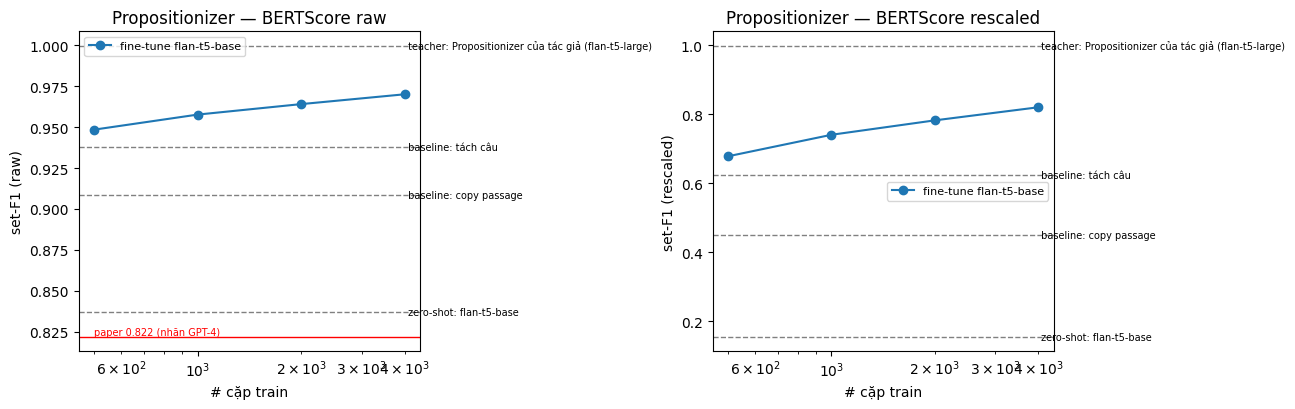

In [9]:
import matplotlib.pyplot as plt
R = pd.DataFrame(RESULTS); display(R)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, k in zip(axes, ["raw", "rescaled"]):
    ft = R[R.system.str.startswith("fine-tune")]
    for mdl, g in ft.groupby("model"):
        ax.plot(g.train_n, g[f"F1_{k}"], marker="o", label=f"fine-tune {mdl}")
    for _, b in R[~R.system.str.startswith("fine-tune")].iterrows():
        ax.axhline(b[f"F1_{k}"], ls="--", lw=1, color="gray"); ax.text(ft.train_n.max(), b[f"F1_{k}"], " " + b.system, va="center", fontsize=7)
    if k == "raw": ax.axhline(0.822, color="red", lw=1); ax.text(ft.train_n.min(), 0.822, "paper 0.822 (nhãn GPT-4)", color="red", fontsize=7, va="bottom")
    ax.set_xscale("log"); ax.set_xlabel("# cặp train"); ax.set_ylabel(f"set-F1 ({k})"); ax.set_title(f"Propositionizer — BERTScore {k}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/figure5_propositionizer.png", dpi=150); plt.show()

## 8. Ví dụ để kiểm tra bằng mắt (tương tự Table 2 — đánh giá thủ công)
Xuất 30 passage dev kèm nhãn, output của model tốt nhất và của teacher → nhóm tự chấm 3 tiêu chí của paper: *faithful*, *minimal*, *stand-alone*.

In [10]:
best = R[R.system.str.startswith("fine-tune")].sort_values("F1_raw").iloc[-1]
key = f"ft-google/{best.model}-{int(best.train_n)}"
ex = pd.DataFrame([{"passage": dev[i]["src"], "reference": "\n".join(dev[i]["props"]),
                    "prediction": "\n".join(PRED_STORE[key][i]),
                    **({"teacher": "\n".join(PRED_STORE["teacher"][i])} if "teacher" in PRED_STORE else {}),
                    "faithful (0/1)": "", "minimal (0/1)": "", "stand_alone (0/1)": ""}
                   for i in random.Random(SEED).sample(range(len(dev)), 30)])
ex.to_csv(f"{OUT}/propositionizer_examples_for_manual_check.csv", index=False)
print("Model tốt nhất:", best.system); display(ex.head(3))
json.dump({"train_shards": train_files, "dev_shards": dev_files, "n_train_pool": len(train_ok), "n_dev": len(dev),
           "page_overlap": 0, "config": {"LR": LR, "WD": WD, "EPOCHS": EPOCHS, "EFF_BATCH": EFF_BATCH, "SEED": SEED}},
          open(f"{OUT}/propositionizer_meta.json", "w"), indent=1)
print("Xong. Tải thư mục", OUT, "→ copy các file vào results/ của repo")

Model tốt nhất: fine-tune: flan-t5-base @ 4000


,passage,reference,prediction,faithful (0/1),minimal (0/1),stand_alone (0/1)
0,Title: Prevention of Crime Act 1959. Section: ...,The Prevention of Crime Act 1959 consists of 5...,The Prevention of Crime Act 1959 is in its cur...,,,
1,Title: Prevention of Animal Cruelty and Provis...,There is only one article in specific to cruel...,There is only one article in specific to cruel...,,,
2,Title: Prevention of HIV/AIDS. Section: Preven...,"As of 2020, no effective vaccine for HIV or AI...","As of 2020, no effective vaccine for HIV or AI...",,,


Xong. Tải thư mục /kaggle/working/propositionizer → copy các file vào results/ của repo
